In [22]:
import pandas as pd 
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [3]:
data = pd.read_csv(r'C:\Users\asus\Desktop\MachineLearning_project\Future Sales Prediction with Machine Learning02\advertising.csv')

In [4]:
print(data.head())

      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9


In [5]:
print(data.isnull().sum())

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


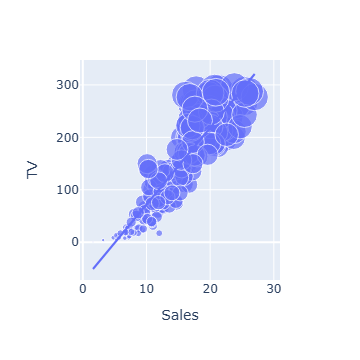

In [7]:
import  plotly.express as px
import plotly.graph_objects as go 
figure =px.scatter(data_frame=data,x="Sales",y="TV",size="TV",trendline='ols')
figure.show()

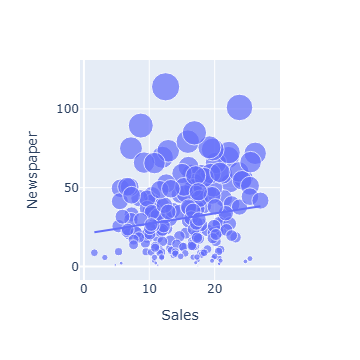

In [8]:
figure = px.scatter(data_frame=data,x="Sales",y="Newspaper",size="Newspaper",trendline="ols")
figure.show()

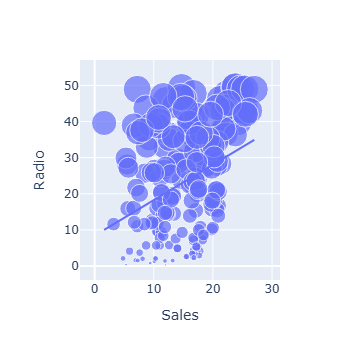

In [10]:
figure=px.scatter(data_frame=data,x="Sales",y="Radio",size="Radio",trendline="ols")
figure.show()

In [14]:
correlation = data.corr()
print(correlation["Sales"].sort_values(ascending=False))

Sales        1.000000
TV           0.901208
Radio        0.349631
Newspaper    0.157960
Name: Sales, dtype: float64


In [17]:
x = np.array(data.drop(['Sales'],axis=1))
y = np.array(data["Sales"])
xtrain,xtest,ytrain,ytest= train_test_split(x,y,test_size=0.2,random_state=42)

In [18]:
model=LinearRegression()
model.fit(xtrain,ytrain)
print(model.score(xtest,ytest))

0.9059011844150826


In [21]:
print(dict(zip(['TV','Radio','Newspaper'], model.coef_.round(3))), model.intercept_)


{'TV': 0.055, 'Radio': 0.101, 'Newspaper': 0.004} 4.714126402214134


In [20]:
pred= model.predict(xtest)
print(pred)


[17.0347724  20.40974033 23.72398873  9.27278518 21.68271879 12.56940161
 21.08119452  8.69035045 17.23701254 16.66657475  8.92396497  8.4817344
 18.2075123   8.06750728 12.64550975 14.93162809  8.12814594 17.89876565
 11.00880637 20.47832788 20.80631846 12.59883297 10.9051829  22.38854775
  9.41796094  7.92506736 20.83908497 13.81520938 10.77080925  7.92682509
 15.95947357 10.63490851 20.80292008 10.43434164 21.5784752  21.18364487
 12.12821771 22.80953262 12.60992766  6.46441252]


In [23]:
print("MAE:",mean_absolute_error(ytest,pred))

MAE: 1.2748262109549342


In [24]:
print("RMSE:",mean_squared_error(ytest,pred)**0.5)

RMSE: 1.705214622934923


In [29]:
score = cross_val_score(LinearRegression(),x,y,cv=5,scoring='r2')
print('R(5-fold)',score.round(3),score.mean().round(3))

R(5-fold) [0.876 0.932 0.922 0.846 0.902] 0.895


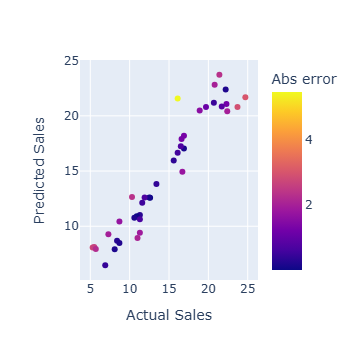

In [37]:
err = abs(ytest-pred)
px.scatter(x=ytest,y=pred,color =err,labels={'x':'Actual Sales','y':'Predicted Sales','color':'Abs error'}).show()

In [38]:
order = np.argsort(err)[::-1][:5]
print(pd.DataFrame(xtest[order], columns=['TV', 'Radio', 'Newspaper'])
        .assign(actual=ytest[order], pred=pred[order], err=err[order]).round(2))

      TV  Radio  Newspaper  actual   pred   err
0  280.7   13.9       37.0    16.1  21.58  5.48
1  220.3   49.0        3.2    24.7  21.68  3.02
2  198.9   49.4       60.0    23.7  20.80  2.90
3    5.4   29.9        9.4     5.3   8.07  2.77
4    7.3   28.1       41.4     5.5   8.13  2.63
